In [19]:
import pandas as pd
import matplotlib.pyplot as plt

In [20]:
df = pd.read_csv('data/salesdaily.csv')

In [21]:
df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


In [22]:
df.tail()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
2101,10/4/2019,7.34,5.683,2.25,22.45,13.0,0.0,1.0,1.00,2019,10,276,Friday
2102,10/5/2019,3.84,5.010,6.00,25.40,7.0,0.0,0.0,0.33,2019,10,276,Saturday
2103,10/6/2019,4.00,11.690,2.00,34.60,6.0,0.0,5.0,4.20,2019,10,276,Sunday
2104,10/7/2019,7.34,4.507,3.00,50.80,6.0,0.0,10.0,1.00,2019,10,276,Monday
2105,10/8/2019,0.33,1.730,0.50,44.30,20.0,2.0,2.0,0.00,2019,10,190,Tuesday


In [23]:
df.describe()

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour
count,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000
mean,5.033683,3.895830,3.880441,29.917095,8.853627,0.593522,5.512262,2.900198,2016.401235,6.344255,275.945869
std,2.737579,2.133337,2.384010,15.590966,5.605605,1.092988,6.428736,2.415816,1.665060,3.386954,1.970547
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014.000000,1.000000,190.000000
25%,3.000000,2.340000,2.000000,19.000000,5.000000,0.000000,1.000000,1.000000,2015.000000,3.000000,276.000000
50%,4.990000,3.670000,3.500000,26.900000,8.000000,0.000000,4.000000,2.000000,2016.000000,6.000000,276.000000
75%,6.670000,5.138000,5.200000,38.300000,12.000000,1.000000,8.000000,4.000000,2018.000000,9.000000,276.000000
max,17.340000,14.463000,16.000000,161.000000,54.833333,9.000000,45.000000,15.000000,2019.000000,12.000000,276.000000


In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   str    
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null   float64
 3   N02BA         2106 non-null   float64
 4   N02BE         2106 non-null   float64
 5   N05B          2106 non-null   float64
 6   N05C          2106 non-null   float64
 7   R03           2106 non-null   float64
 8   R06           2106 non-null   float64
 9   Year          2106 non-null   int64  
 10  Month         2106 non-null   int64  
 11  Hour          2106 non-null   int64  
 12  Weekday Name  2106 non-null   str    
dtypes: float64(8), int64(3), str(2)
memory usage: 214.0 KB


In [25]:
df.isnull().sum()

datum           0
M01AB           0
M01AE           0
N02BA           0
N02BE           0
N05B            0
N05C            0
R03             0
R06             0
Year            0
Month           0
Hour            0
Weekday Name    0
dtype: int64

In [26]:
drug_columns = [
    'M01AB', 'M01AE', 'N02BA', 'N02BE',
    'N05B', 'N05C', 'R03', 'R06'
]

total_sales = df[drug_columns].sum().sort_values(ascending=False)

print(total_sales)

N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64


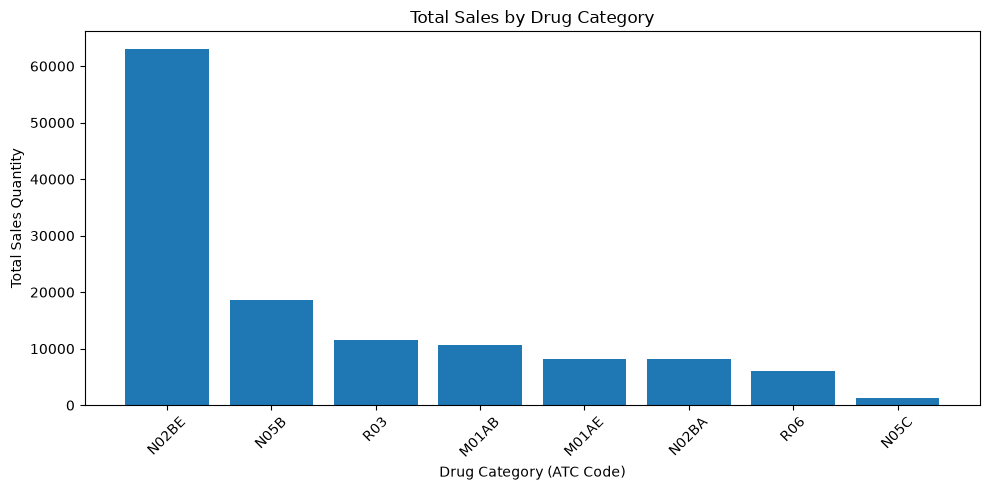

In [27]:
plt.figure(figsize=(10, 5))

plt.bar(total_sales.index, total_sales.values)

plt.title('Total Sales by Drug Category')
plt.xlabel('Drug Category (ATC Code)')
plt.ylabel('Total Sales Quantity')

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("visualizations/total_sales_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
selected_periods = [
    (2015, 1),
    (2016, 7),
    (2017, 9)
]

for year, month in selected_periods:

    monthly_data = df[
        (df['Year'] == year) &
        (df['Month'] == month)
    ]

    monthly_sales = monthly_data[drug_columns].sum()

    top_three = monthly_sales.sort_values(
        ascending=False
    ).head(3)

    print(f"\nTop 3 drug categories - {year}/{month}")
    print(top_three)


Top 3 drug categories - 2015/1
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

Top 3 drug categories - 2016/7
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

Top 3 drug categories - 2017/9
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64


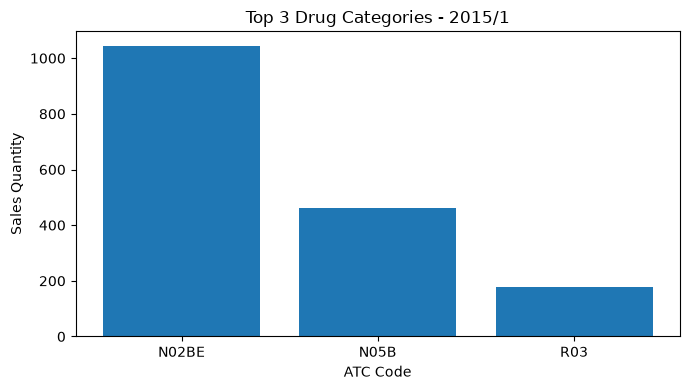

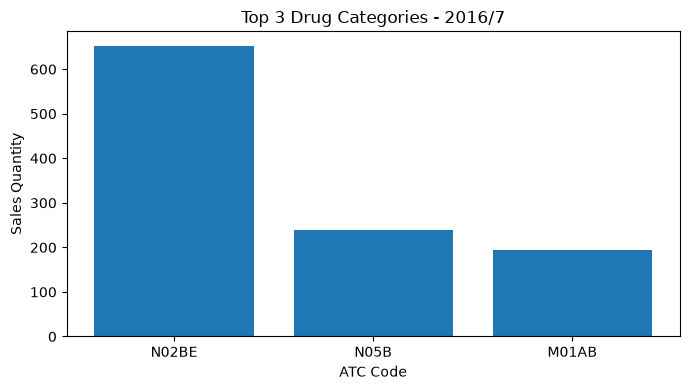

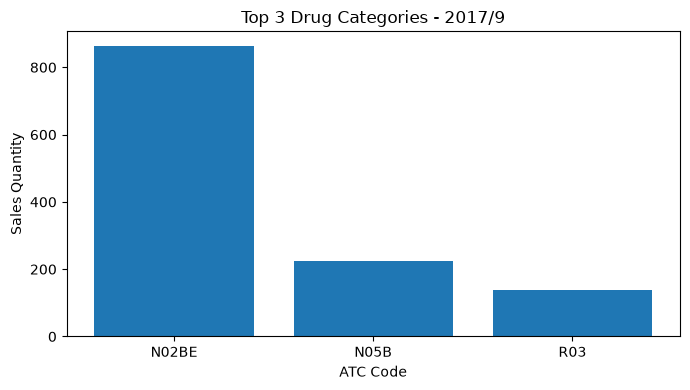

In [29]:
for year, month in selected_periods:

    monthly_data = df[
        (df['Year'] == year) &
        (df['Month'] == month)
    ]

    monthly_sales = monthly_data[drug_columns].sum()

    top_three = monthly_sales.sort_values(
        ascending=False
    ).head(3)

    plt.figure(figsize=(7, 4))

    plt.bar(top_three.index, top_three.values)

    plt.title(f'Top 3 Drug Categories - {year}/{month}')
    plt.xlabel('ATC Code')
    plt.ylabel('Sales Quantity')

    plt.tight_layout()
    plt.savefig(f"visualizations/top_3_categories_{year}_{month}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [30]:
sales_2017 = df[df['Year'] == 2017]

sales_by_drug_2017 = (
    sales_2017[drug_columns]
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_drug_2017)

N02BE    9258.804833
N05B     2555.541667
R03      1893.614583
M01AB    1846.617083
M01AE    1387.298333
N02BA    1288.295833
R06       988.860000
N05C      180.333333
dtype: float64


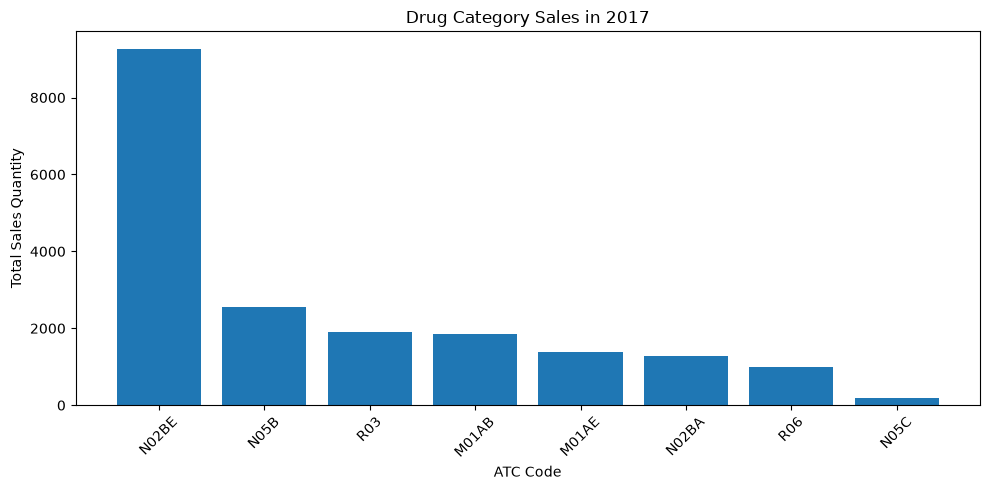

In [31]:
plt.figure(figsize=(10, 5))

plt.bar(
    sales_by_drug_2017.index,
    sales_by_drug_2017.values
)

plt.title('Drug Category Sales in 2017')
plt.xlabel('ATC Code')
plt.ylabel('Total Sales Quantity')

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("visualizations/drug_sales_2017.png", dpi=300, bbox_inches="tight")
plt.show()

In [32]:
average_daily_sales = (
    df[drug_columns]
    .mean()
    .sort_values(ascending=False)
)

print(average_daily_sales)

N02BE    29.917095
N05B      8.853627
R03       5.512262
M01AB     5.033683
M01AE     3.895830
N02BA     3.880441
R06       2.900198
N05C      0.593522
dtype: float64


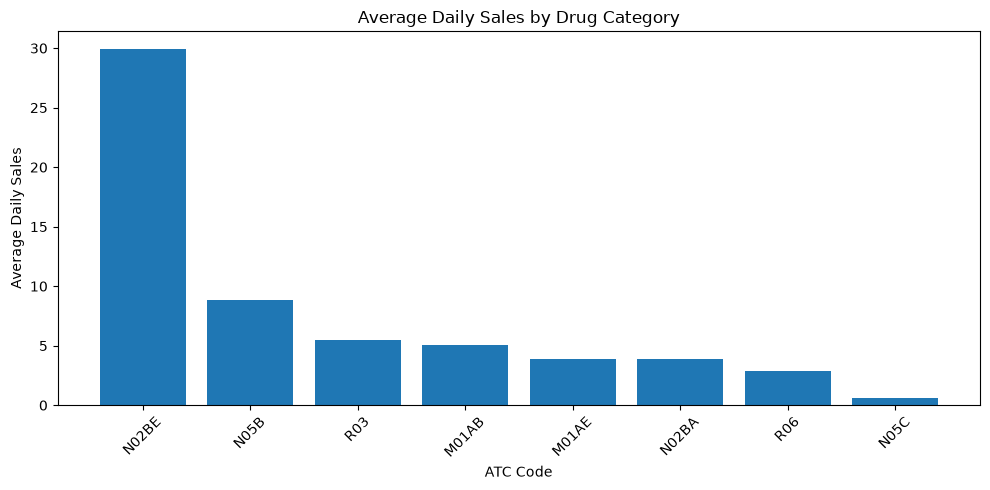

In [33]:
plt.figure(figsize=(10, 5))

plt.bar(
    average_daily_sales.index,
    average_daily_sales.values
)

plt.title('Average Daily Sales by Drug Category')
plt.xlabel('ATC Code')
plt.ylabel('Average Daily Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("visualizations/average_daily_sales.png", dpi=300, bbox_inches="tight")
plt.show()

In [34]:
monthly_r03_sales = df.groupby('Month')['R03'].mean()

print(monthly_r03_sales)

Month
1     6.835980
2     6.896943
3     6.290323
4     5.771528
5     5.006944
6     4.350000
7     2.956989
8     3.102151
9     4.402315
10    7.208589
11    6.226667
12    7.916129
Name: R03, dtype: float64


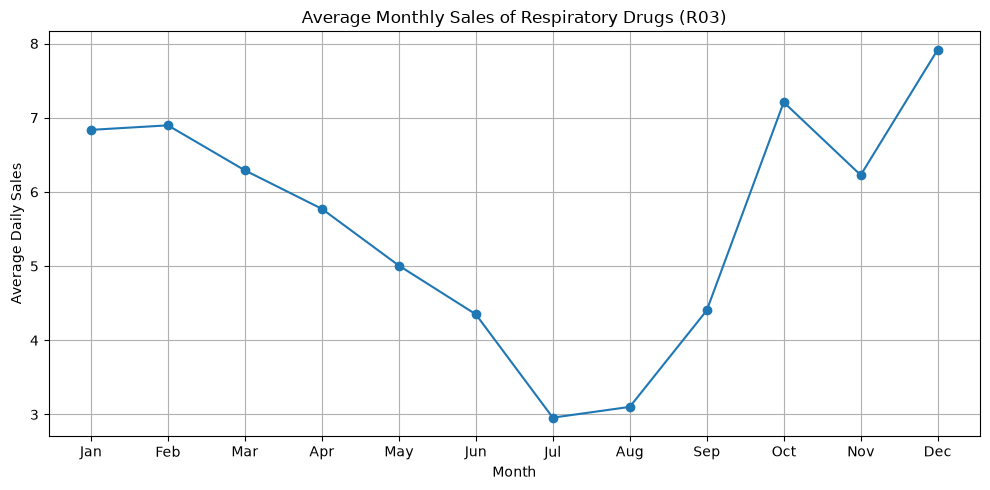

In [35]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_r03_sales.index,
    monthly_r03_sales.values,
    marker='o'
)

plt.title('Average Monthly Sales of Respiratory Drugs (R03)')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales')

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.grid(True)
plt.tight_layout()
plt.savefig("visualizations/monthly_r03_sales.png", dpi=300, bbox_inches="tight")
plt.show()